# code_024 · Regularization and inductive bias

**Book:** section 5.3. These are synthetic mechanism experiments, not observed structural performance, safety assessment, a causal study or an estimator leaderboard. Each experiment states which cases are unseen and which outcomes are available. Fits and preprocessing use training observations only. Development curves support diagnosis; final outcomes are opened only after the stated rule is fixed. Constructed identities and stress cases are not held-out population estimates.

Restart and run all cells. All imports, helpers and data generation are here; no ordinary-run files, network, API key, GPU or private module is required. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [traceability guide](../CHAPTER_05_GUIDE.md), [execution evidence](../CHAPTER_05_EXECUTION.md) and [permanent registry](../CODE_EXAMPLES.md#code_024). Reference environment: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute for execution and 30–60 minutes for interpretation. These scoped labs disclose relevant controls rather than cover every constructor parameter.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=524;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 524


<a id="lenses"></a>
## Different completions of the same observations

Generate one-dimensional monotone response f(x)=.2+x+.35*x² with training x in [.1,.85], independent Gaussian noise sd .1 mm. A line, cubic spline plus ridge, shallow local tree and isotonic predictor see identical 50 training rows. Spline knots, fitted coefficients and tree splits use training data only. The shaded outside region is unsupported by the training range. Extrapolation is a software rule, not new evidence.

Controls: SplineTransformer(n_knots=5,degree=3,extrapolation='linear') then Ridge(alpha=.1); DecisionTreeRegressor(max_depth=3,min_samples_leaf=5,random_state=SEED); IsotonicRegression(increasing=True,out_of_bounds='clip'). The straight line uses least squares. This illustration does not rank model families.


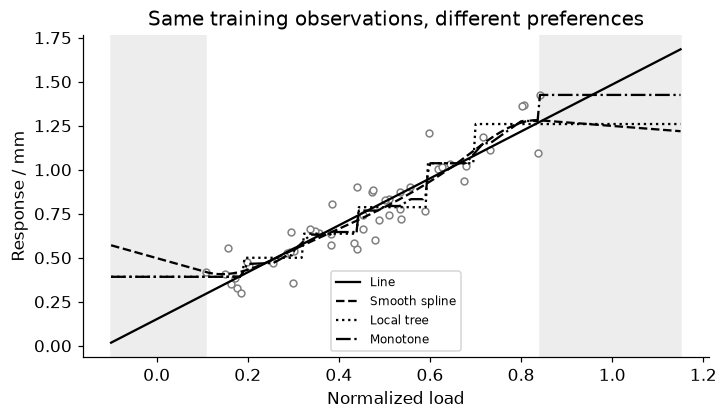

In [2]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import SplineTransformer,StandardScaler
from sklearn.linear_model import Ridge,LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.isotonic import IsotonicRegression
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
x=rng.uniform(.1,.85,50);y=.2+x+.35*x*x+rng.normal(0,.1,len(x));grid=np.linspace(-.1,1.15,240)
models=[LinearRegression(),make_pipeline(SplineTransformer(n_knots=5,degree=3,extrapolation='linear'),Ridge(alpha=.1)),DecisionTreeRegressor(max_depth=3,min_samples_leaf=5,random_state=SEED)]
for model in models:model.fit(x[:,None],y)
iso=IsotonicRegression(increasing=True,out_of_bounds='clip').fit(x,y)
preds=[m.predict(grid[:,None]) for m in models]+[iso.predict(grid)]
assert np.min(np.diff(preds[-1]))>=-1e-12 and all(np.isfinite(p).all() for p in preds)
fig,ax=plt.subplots(figsize=(6.5,3.7));ax.axvspan(grid.min(),x.min(),color='.93');ax.axvspan(x.max(),grid.max(),color='.93');ax.scatter(x,y,s=20,facecolors='white',edgecolors='.5')
for p,style,name in zip(preds,['-','--',':','-.'],['Line','Smooth spline','Local tree','Monotone']):ax.plot(grid,p,color='black',ls=style,label=name)
ax.set(xlabel='Normalized load',ylabel='Response / mm',title='Same training observations, different preferences');ax.legend(fontsize=8);plt.show()
RESULTS['training_support']=[float(x.min()),float(x.max())]


<a id="shrinkage"></a>
## Penalties and stopping act through coordinates and dynamics

A separate centered three-feature linear training problem uses mean half squared loss. Ridge with lambda=.2 penalizes every coefficient; there is no intercept in this centered demonstration. Solve the augmented least-squares system [X/sqrt(n);sqrt(lambda)*I] rather than invert X.T@X. Gradient descent from zero with eta=.2 and no penalty is stopped at 20 updates; its eventual unpenalized limit is also computed. Early stopping and ridge are different spectral preferences and need not give identical coefficients.

**Predict:** if one feature is multiplied by ten and its coefficient divided by ten, does an unadjusted L2 penalty preserve the same preference?


In [3]:
z=rng.normal(size=80);X=np.column_stack([z,z+.1*rng.normal(size=80),rng.normal(size=80)]);X-=X.mean(0);target=1.2*z+rng.normal(0,.25,80);target-=target.mean();n=len(target);lam=.2
ridge=np.linalg.lstsq(np.vstack([X/np.sqrt(n),np.sqrt(lam)*np.eye(3)]),np.r_[target/np.sqrt(n),np.zeros(3)],rcond=None)[0]
ols=np.linalg.lstsq(X,target,rcond=None)[0];w=np.zeros(3);eta=.2;history=[]
for step in range(400):
 w-=eta*X.T@(X@w-target)/n
 history.append(w.copy())
early=history[19]
assert np.linalg.norm(X.T@(X@ridge-target)/n+lam*ridge)<1e-12
assert np.linalg.norm(ridge)<np.linalg.norm(ols) and not np.allclose(early,ridge)
scaled=X.copy();scaled[:,0]*=10;equivalent=ols.copy();equivalent[0]/=10
assert np.allclose(scaled@equivalent,X@ols) and not np.isclose(equivalent@equivalent,ols@ols)
print(pd.DataFrame({'OLS':ols,'ridge':ridge,'stop_at_20':early}))
RESULTS['coefficient_norms_OLS_ridge_early']=[float(np.linalg.norm(v)) for v in [ols,ridge,early]]


        OLS     ridge  stop_at_20
0  0.742438  0.533186    0.602999
1  0.482647  0.543475    0.616752
2 -0.005953 -0.006903   -0.008575


<a id="families"></a>
## Additive, monotone and unconstrained deep rules

Separate two-feature data: y=.2+x0+.35*x0²+.25*x1+noise (.08 mm sd). x0 is load coordinate and x1 a dimensionless temperature coordinate. Fixed independent roles: 240 training, 100 development and 100 final members. A spline transform applied separately to each feature plus Ridge is additive (no cross-feature interactions). A histogram boosted tree uses monotonic_cst=[1,0], enforcing nondecrease only in x0 at fixed x1. An actual MLP with two hidden layers (24,24), tanh activation and lbfgs training has no hard monotonicity or additivity restriction. StandardScaler is fitted inside its training pipeline.

Fixed controls: additive n_knots=5,degree=3,alpha=.1; HGBT max_iter=120,max_leaf_nodes=7,min_samples_leaf=15,learning_rate=.08,l2_regularization=1,early_stopping=False; MLP alpha=.01,max_iter=3000,max_fun=50000,tol=1e-6,random_state=SEED. No parameter grid or equal-compute comparison is claimed. Inspect development, then open final once for all three predeclared mechanisms; do not select a winner from final outcomes.


Development RMSE [mm]: {'smooth_additive': 0.08329287473564742, 'monotone_tree': 0.09059665465987095, 'deep_MLP': 0.08450575707930337}


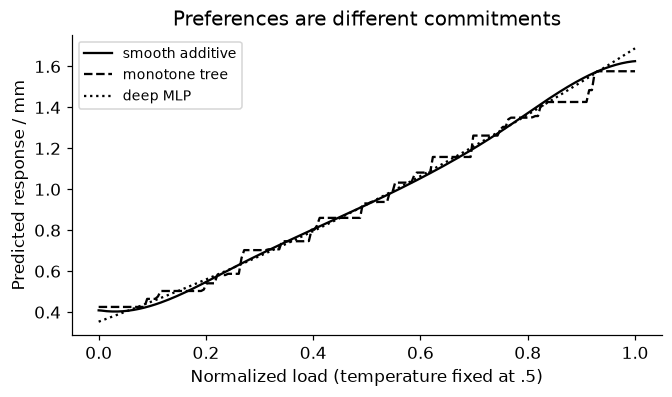

Final, predeclared-model RMSE [mm]: {'smooth_additive': 0.08605126303954778, 'monotone_tree': 0.09592112256127082, 'deep_MLP': 0.08631839462962293}


In [4]:
Z=rng.uniform(0,1,(440,2));target=.2+Z[:,0]+.35*Z[:,0]**2+.25*Z[:,1]+rng.normal(0,.08,440);tr=np.arange(240);dv=np.arange(240,340);te=np.arange(340,440)
families={
 'smooth_additive':make_pipeline(SplineTransformer(n_knots=5,degree=3),Ridge(alpha=.1)),
 'monotone_tree':HistGradientBoostingRegressor(monotonic_cst=[1,0],max_iter=120,max_leaf_nodes=7,min_samples_leaf=15,learning_rate=.08,l2_regularization=1.,early_stopping=False,random_state=SEED),
 'deep_MLP':make_pipeline(StandardScaler(),MLPRegressor(hidden_layer_sizes=(24,24),activation='tanh',solver='lbfgs',alpha=.01,max_iter=3000,max_fun=50000,tol=1e-6,random_state=SEED))}
for model in families.values():model.fit(Z[tr],target[tr])
assert not set(tr)&set(dv) and not set(tr)&set(te)
print('Development RMSE [mm]:',{k:float(np.sqrt(np.mean((m.predict(Z[dv])-target[dv])**2))) for k,m in families.items()})
line=np.column_stack([np.linspace(0,1,200),np.full(200,.5)])
mono=families['monotone_tree'].predict(line);assert np.min(np.diff(mono))>=-1e-12
mlp=families['deep_MLP'][-1];assert mlp.n_layers_==4 and len(mlp.hidden_layer_sizes)==2 and mlp.n_iter_<3000
# A rectangular contrast is zero for an additive predictor.
corners=np.array([[.2,.3],[.8,.3],[.2,.7],[.8,.7]]);v=families['smooth_additive'].predict(corners)
assert abs(v[0]-v[1]-v[2]+v[3])<1e-10
fig,ax=plt.subplots(figsize=(6,3.5))
for (name,model),style in zip(families.items(),['-','--',':']):ax.plot(line[:,0],model.predict(line),color='black',ls=style,label=name.replace('_',' '))
ax.set(xlabel='Normalized load (temperature fixed at .5)',ylabel='Predicted response / mm',title='Preferences are different commitments');ax.legend(fontsize=9);plt.show()
final={k:float(np.sqrt(np.mean((m.predict(Z[te])-target[te])**2))) for k,m in families.items()}
assert all(np.isfinite(list(final.values())))
print('Final, predeclared-model RMSE [mm]:',final);RESULTS['final_family_RMSE_mm']=final;RESULTS['MLP_iterations']=int(mlp.n_iter_)


<a id="augmentation"></a>
## Augmentation requires a valid target transformation

For an ideal isotropic two-dimensional spring with K=kI, scalar displacement magnitude is ||f||/k. Rotating the force preserves that scalar target. This constructed identity checks the augmentation assumption; it does not demonstrate a general training benefit. With direction-dependent stiffness fixed in physical space, the same rotation need not preserve the target. code_026 tests that failure.


In [5]:
force=np.array([300.,400.]);angle=.7;R=np.array([[np.cos(angle),-np.sin(angle)],[np.sin(angle),np.cos(angle)]])
k=1000.;original=np.linalg.norm(force)/k;rotated=np.linalg.norm(R@force)/k
assert np.allclose(R.T@R,np.eye(2)) and np.isclose(original,rotated) and np.isclose(original,.5)
RESULTS['isotropic_rotation_displacement_m']=float(original)


<a id="exercises"></a>
## Exercises and hints

1. Penalize only a slope, leaving an intercept unpenalized. Reconcile the loss normalization with the library alpha convention.
2. Change input units and compare a fixed raw-coordinate penalty with a training-only standardized pipeline.
3. Add a load–temperature interaction to the generator. Test the additive commitment using development evidence and new final data.
4. Introduce a response that falls after a peak load. Explain why a hard increasing constraint cannot represent the whole regime.
5. Record early stopping's monitored data, patience and checkpoint rule. Keep the final sample outside that process.

**Hints:** a smaller weight is meaningful only relative to feature units. Augmentation contributes a preference plus correlated constructed examples, not independent measured cases. Hard structural constraints differ from a finite penalty. See official [monotonic constraints](https://scikit-learn.org/1.9/auto_examples/ensemble/plot_monotonic_constraints.html) and [MLPRegressor](https://scikit-learn.org/1.9/modules/generated/sklearn.neural_network.MLPRegressor.html) documentation.


In [6]:
summary={'example_id':'code_024','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['same-data line smooth local monotone lenses', 'ridge shrinkage coordinate dependence', 'early stopping as a preference', 'smooth additive versus monotone versus deep predictors', 'valid augmentation under a declared symmetry'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["same-data line smooth local monotone lenses", "ridge shrinkage coordinate dependence", "early stopping as a preference", "smooth additive versus monotone versus deep predictors", "valid augmentation under a declared symmetry"], "elapsed_seconds": 0.542, "example_id": "code_024", "hardware": "Darwin arm64 CPU", "results": {"MLP_iterations": 440, "coefficient_norms_OLS_ridge_early": [0.8855492290489336, 0.7613803029702881, 0.8625911116419587], "final_family_RMSE_mm": {"deep_MLP": 0.08631839462962293, "monotone_tree": 0.09592112256127082, "smooth_additive": 0.08605126303954778}, "isotropic_rotation_displacement_m": 0.5, "training_support": [0.10787276036234039, 0.8411363691778642]}, "seed": 524, "versions": {"matplotlib": "3.11.0", "numpy": "2.4.4", "pandas": "3.0.3", "python": "3.14.3", "scikit-learn": "1.9.0", "scipy": "1.17.1"}}
